# 07 — Nested Temporal Cross-Validation

## Notebook description

This notebook estimates how regression and high-demand classification models perform across later time windows. Each outer validation window is kept out of fitting and hyperparameter selection; within each outer training period, inner rolling windows select complete preprocessing-and-model pipelines. The final configurations are then refitted on development data; the complete test period is reported as exploratory because an earlier notebook version already displayed test outcomes.

## Objectives

- Define transparent inner and outer chronological windows.
- Tune complete pipelines rather than isolated estimators.
- Use a small, reproducible search space and compute budget.
- Report fold-level performance and configuration stability.
- Select regression and classification configurations using development data only.
- Report exploratory test scores after freezing the design, with an explicit interpretation limit.

## Planned sections

1. Nested temporal-validation design
2. Shared reproducibility and leakage controls
3. Regression search space and inner-loop tuning
4. Regression outer-loop estimates
5. Classification search space and inner-loop tuning
6. Classification outer-loop estimates
7. Configuration selection and stability
8. Final-test evaluation and interpretation limit

The nested temporal search uses a deterministic sample within each target week. Its fold estimates apply to that sample. Section 8 reloads the complete publication, refits the selected configurations on every train and validation row, and evaluates every test row. That full-period test is exploratory because earlier test outcomes have already been inspected.


## 1. Nested temporal-validation design

The original data contract assigns complete target weeks to chronological `train`, `validation`, and `test` partitions. Nested outer folds are built only from the combined development weeks (`train` + `validation`); the final test weeks do not participate in cross-validation. Each outer fold predicts a later block of weeks using all earlier development weeks. Its inner folds are rolling-origin splits inside that outer training period.

Default compute budget: 3 outer folds × 4 validation weeks, 2 inner folds × 3 validation weeks, and at most 2.000 sampled article-weeks per partition-week. These are explicit iteration settings, not statistical necessities. If the publication has too few weeks for the requested design, the notebook stops with an explanatory error rather than silently changing the protocol.

🔴 **Data used by this notebook (Iratxe, 27 October 2026).** Notebook 02 prepared run `20261027T145552-5a1ac59a`, selected by `data/processed/CURRENT.json`. It includes `target_high_demand` and all columns required here. High demand means at least **16 next-week sales**; the **more than 20 sales** groups below are only for error analysis. All code cells were rerun with this data. The test scores are exploratory because test outcomes had already been shown in an earlier notebook version.

**Code walkthrough.** The next cell finds the published data, verifies the file checksum, keeps a reproducible sample from every week, and builds three later validation windows. It does not fit a model.


In [1]:
from hashlib import sha256
import json
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    HistGradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

RANDOM_STATE = 42
MAX_ROWS_PER_WEEK = 2_000
CHUNK_SIZE = 250_000
OUTER_FOLDS = 3
OUTER_HORIZON_WEEKS = 4
INNER_FOLDS = 2
INNER_HORIZON_WEEKS = 3
MIN_TRAIN_WEEKS = 20
TARGET_CLASS = "target_high_demand"
TARGET_REGRESSION = "target_next_week_sales"

ROOT = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "src/data/process_data.py").is_file()
        and (path / "data/processed/CURRENT.json").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "No complete publication found. Run `python src/data/process_data.py` "
        "from the project root first."
    )
sys.path.insert(0, str(ROOT))
import importlib
import src.visualization.style as chart_style
importlib.reload(chart_style)
from src.visualization.style import (
    BLUE, GOLD, GRID, INK, MUTED, PAPER, VIOLET, apply_style, display_es, es, format_number, format_percent, add_source, add_title,
)
apply_style()

processed_dir = ROOT / "data/processed"
pointer = json.loads((processed_dir / "CURRENT.json").read_text(encoding="utf-8"))
run_dir = (processed_dir / pointer["run_dir"]).resolve()
if not run_dir.is_relative_to(processed_dir.resolve()) or pointer.get("preview"):
    raise ValueError("CURRENT.json does not reference a valid complete publication.")

checksums = json.loads((run_dir / "checksums.json").read_text(encoding="utf-8"))
dataset_path = run_dir / "article_week.csv.gz"
digest = sha256()
with dataset_path.open("rb") as stream:
    for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
        digest.update(block)
if checksums.get(dataset_path.name) != digest.hexdigest():
    raise ValueError("article_week.csv.gz does not match its recorded SHA-256 checksum.")

summary = json.loads((run_dir / "summary.json").read_text(encoding="utf-8"))
classification_definition = summary.get("classification_target")
if not classification_definition or "threshold_units" not in classification_definition:
    raise ValueError("summary.json has no valid high-demand target definition.")
HIGH_DEMAND_THRESHOLD = int(classification_definition["threshold_units"])

NUMERIC_FEATURES = [
    "sales", "lag_1_sales", "lag_2_sales", "lag_4_sales", "lag_12_sales",
    "rolling_4w_sales_mean", "rolling_4w_sales_std", "rolling_4w_active_weeks",
    "rolling_12w_sales_mean", "rolling_12w_sales_std", "rolling_12w_active_weeks",
    "sales_trend_4w", "mean_price", "rolling_4w_mean_price",
    "price_change_from_4w_mean", "rolling_4w_online_share", "week_sin", "week_cos",
]
CATEGORICAL_FEATURES = [
    "product_type_name", "product_group_name", "index_group_name",
    "section_name", "garment_group_name", "colour_group_name",
]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
SAMPLED_COLUMNS = [
    "article_id", "split", "target_week", "iso_week", "sales",
    "target_next_week_sales", "target_high_demand",
    "lag_1_sales", "lag_2_sales", "lag_3_sales", "lag_4_sales", "lag_12_sales",
    "rolling_4w_sales_mean", "rolling_4w_sales_std", "rolling_4w_active_weeks",
    "rolling_12w_sales_mean", "rolling_12w_sales_std", "rolling_12w_active_weeks",
    "sales_trend_4w", "mean_price", "rolling_4w_mean_price",
    "price_change_from_4w_mean", "rolling_4w_online_share",
    *CATEGORICAL_FEATURES,
]
required_source_columns = set(SAMPLED_COLUMNS)
sample_candidates = []

for chunk_number, chunk in enumerate(
    pd.read_csv(
        dataset_path,
        usecols=SAMPLED_COLUMNS,
        dtype={"article_id": "string"},
        parse_dates=["target_week"],
        chunksize=CHUNK_SIZE,
    )
):
    chunk = chunk.loc[chunk["split"].isin(["train", "validation", "test"])].copy()
    if chunk.empty:
        continue

    sample_key = (
        chunk["article_id"].astype("string")
        + "|"
        + chunk["target_week"].dt.strftime("%Y-%m-%d")
    )
    chunk["_sample_hash"] = pd.util.hash_pandas_object(
        sample_key, index=False, hash_key="fashion-demand07"
    ).to_numpy(dtype="uint64")

    for _, week_group in chunk.groupby(
        ["split", "target_week"], sort=False, observed=True
    ):
        sample_candidates.append(
            week_group.nsmallest(MAX_ROWS_PER_WEEK, "_sample_hash")
        )

if not sample_candidates:
    raise ValueError("No train, validation, or test rows were found in the publication.")

candidate_data = pd.concat(sample_candidates, ignore_index=True)
sampled_parts = []
for _, week_group in candidate_data.groupby(
    ["split", "target_week"], sort=False, observed=True
):
    sampled_parts.append(week_group.nsmallest(MAX_ROWS_PER_WEEK, "_sample_hash"))
model_data = pd.concat(sampled_parts, ignore_index=True).drop(
    columns=["article_id", "_sample_hash"]
)

missing_columns = sorted(required_source_columns - {"article_id"} - set(model_data.columns))
if missing_columns:
    raise ValueError(f"Required modeling columns are missing: {missing_columns}")
if model_data[["target_week", "split", TARGET_REGRESSION, TARGET_CLASS]].isna().any().any():
    raise ValueError("Sampled rows contain missing split, target-week, or target values.")
if not model_data[TARGET_CLASS].isin([0, 1]).all():
    raise ValueError("target_high_demand must contain only binary labels.")
expected_class = model_data[TARGET_REGRESSION].ge(HIGH_DEMAND_THRESHOLD).astype("int8")
if not np.array_equal(model_data[TARGET_CLASS].to_numpy(dtype="int8"), expected_class.to_numpy()):
    raise ValueError("Sampled classification labels do not match the fixed target threshold.")

model_data["iso_week"] = model_data["iso_week"].astype(int)
model_data["week_sin"] = np.sin(2 * np.pi * (model_data["iso_week"] - 1) / 52.1775)
model_data["week_cos"] = np.cos(2 * np.pi * (model_data["iso_week"] - 1) / 52.1775)
for column in CATEGORICAL_FEATURES:
    model_data[column] = model_data[column].fillna("Unknown").astype(str)

development = model_data.loc[model_data["split"].isin(["train", "validation"])].copy()
test_sample = model_data.loc[model_data["split"].eq("test")].copy()  # Only for design checks; final scoring reloads every test row.
development_weeks = pd.DatetimeIndex(sorted(development["target_week"].unique()))
train_weeks = pd.DatetimeIndex(sorted(model_data.loc[model_data["split"].eq("train"), "target_week"].unique()))
validation_weeks = pd.DatetimeIndex(sorted(model_data.loc[model_data["split"].eq("validation"), "target_week"].unique()))
test_weeks = pd.DatetimeIndex(sorted(test_sample["target_week"].unique()))
if development.empty or test_sample.empty:
    raise ValueError("Both development and reserved test partitions must be non-empty.")
if test_sample[TARGET_CLASS].nunique() != 2:
    raise ValueError("The reserved test sample must contain both classification classes.")
if len(development_weeks) < MIN_TRAIN_WEEKS + OUTER_FOLDS * OUTER_HORIZON_WEEKS:
    raise ValueError("Too few development weeks for the configured outer temporal folds.")
for partition_weeks in (development_weeks, test_weeks):
    if (partition_weeks.weekday != 0).any():
        raise ValueError("Target-week dates must be Monday-based weekly boundaries.")
    expected_weeks = pd.date_range(
        partition_weeks.min(), partition_weeks.max(), freq="W-MON"
    )
    if not partition_weeks.equals(expected_weeks):
        raise ValueError("A development or test partition contains missing target weeks.")
if len(train_weeks) and len(validation_weeks) and train_weeks.max() >= validation_weeks.min():
    raise ValueError("Train and validation weeks overlap or are not chronological.")
if len(validation_weeks) and len(test_weeks) and validation_weeks.max() >= test_weeks.min():
    raise ValueError("Validation and test weeks overlap or are not chronological.")

outer_folds = []
first_outer_start = len(development_weeks) - OUTER_FOLDS * OUTER_HORIZON_WEEKS
for fold_number in range(OUTER_FOLDS):
    start = first_outer_start + fold_number * OUTER_HORIZON_WEEKS
    validation_fold_weeks = development_weeks[start : start + OUTER_HORIZON_WEEKS]
    training_fold_weeks = development_weeks[:start]
    if len(training_fold_weeks) < MIN_TRAIN_WEEKS:
        raise ValueError(f"Outer fold {fold_number + 1} has too few training weeks.")
    outer_folds.append(
        {
            "fold": fold_number + 1,
            "train_weeks": training_fold_weeks,
            "validation_weeks": validation_fold_weeks,
        }
    )

def make_inner_folds(outer_training_weeks):
    required_weeks = INNER_FOLDS * INNER_HORIZON_WEEKS
    if len(outer_training_weeks) < MIN_TRAIN_WEEKS + required_weeks:
        raise ValueError("An outer training window is too short for the inner CV design.")
    first_start = len(outer_training_weeks) - required_weeks
    folds = []
    for fold_number in range(INNER_FOLDS):
        start = first_start + fold_number * INNER_HORIZON_WEEKS
        validation_fold_weeks = outer_training_weeks[
            start : start + INNER_HORIZON_WEEKS
        ]
        training_fold_weeks = outer_training_weeks[:start]
        if len(training_fold_weeks) < MIN_TRAIN_WEEKS:
            raise ValueError(f"Inner fold {fold_number + 1} has too few training weeks.")
        folds.append(
            {
                "fold": fold_number + 1,
                "train_weeks": training_fold_weeks,
                "validation_weeks": validation_fold_weeks,
            }
        )
    return folds

fold_rows = []
for fold in outer_folds:
    fold_rows.append(
        {
            "outer_fold": fold["fold"],
            "train_start": fold["train_weeks"].min(),
            "train_end": fold["train_weeks"].max(),
            "outer_validation_start": fold["validation_weeks"].min(),
            "outer_validation_end": fold["validation_weeks"].max(),
            "train_sample_rows": int(development["target_week"].isin(fold["train_weeks"]).sum()),
            "outer_validation_sample_rows": int(development["target_week"].isin(fold["validation_weeks"]).sum()),
        }
    )
outer_fold_table = pd.DataFrame(fold_rows)

def style_axis(axis):
    axis.set_axisbelow(True)
    axis.grid(axis="y", color=GRID, linewidth=0.7, alpha=0.8)
    for side in ("top", "right"):
        axis.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        axis.spines[side].set_color(GRID)

print("Run:", run_dir.name)
print(f"Rows sampled: {es(len(model_data)):,} total; at most {es(MAX_ROWS_PER_WEEK):,} per target week and partition.")
print(f"Development: {es(len(development)):,} sampled rows over {len(development_weeks)} weeks.")
print(f"Reserved test: {es(len(test_sample)):,} sampled rows over {len(test_weeks)} weeks.")
print(f"Class definition: next-week sales >= {HIGH_DEMAND_THRESHOLD}; fixed by notebook 02.")
print(f"Temporal design: {OUTER_FOLDS} outer folds x {OUTER_HORIZON_WEEKS} weeks; {INNER_FOLDS} inner folds x {INNER_HORIZON_WEEKS} weeks.")
print("A reserved test sample is used only for design checks here; section 8 reloads the complete test partition.")
display_es(outer_fold_table)


Run: 20261024T182146-1559e91a
Rows sampled: 182.000 total; at most 2.000 per target week and partition.
Development: 154.000 sampled rows over 77 weeks.
Reserved test: 28.000 sampled rows over 14 weeks.
Class definition: next-week sales >= 16; fixed by notebook 02.
Temporal design: 3 outer folds x 4 weeks; 2 inner folds x 3 weeks.
A reserved test sample is used only for design checks here; section 8 reloads the complete test partition.


,outer_fold,train_start,train_end,outer_validation_start,outer_validation_end,train_sample_rows,outer_validation_sample_rows
0,1,2018-12-24 00:00:00,2020-03-16 00:00:00,2020-03-23 00:00:00,2020-04-13 00:00:00,130.000,8.000
1,2,2018-12-24 00:00:00,2020-04-13 00:00:00,2020-04-20 00:00:00,2020-05-11 00:00:00,138.000,8.000
2,3,2018-12-24 00:00:00,2020-05-11 00:00:00,2020-05-18 00:00:00,2020-06-08 00:00:00,146.000,8.000


## 2. Shared reproducibility and leakage controls

The target-week boundaries are the sole split mechanism; no random row-level cross-validation is used. Every inner-fold pipeline learns imputations, scaling, category handling, and model parameters from its inner training rows. Outer validation weeks are used only to estimate the complete inner-selection procedure. Target columns, split labels, identifiers, and target-week dates are not predictors.

Regression uses MAE to select configurations because it is interpretable in recorded units and less dominated by extreme sales than RMSE. Classification uses average precision (PR-AUC), which is more informative than accuracy for the roughly one-in-five positive class. The probability decision threshold for classification stays fixed at 0,5 in this notebook; threshold optimization is a separate question.

**Code walkthrough.** The next cell lists the allowed predictors, prepares missing values and categories inside each training fold, and defines the error calculations used throughout the notebook.


In [2]:
NUMERIC_FEATURES = [
    "sales", "lag_1_sales", "lag_2_sales", "lag_4_sales", "lag_12_sales",
    "rolling_4w_sales_mean", "rolling_4w_sales_std", "rolling_4w_active_weeks",
    "rolling_12w_sales_mean", "rolling_12w_sales_std", "rolling_12w_active_weeks",
    "sales_trend_4w", "mean_price", "rolling_4w_mean_price",
    "price_change_from_4w_mean", "rolling_4w_online_share", "week_sin", "week_cos",
]
FORBIDDEN_PREDICTORS = {
    "article_id", "product_code", TARGET_REGRESSION, TARGET_CLASS,
    "target_week", "split", "target_is_observed", "history_is_observed",
}
if FORBIDDEN_PREDICTORS.intersection(FEATURES):
    raise ValueError("A target, identifier, or future-period field is present among predictors.")
if set(FEATURES) != set(NUMERIC_FEATURES + CATEGORICAL_FEATURES):
    raise ValueError("Feature definitions are inconsistent.")

numeric_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=25,
                max_categories=80,
                sparse_output=True,
            ),
        ),
    ]
)
preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ],
    remainder="drop",
    sparse_threshold=0.3,
)

# Histogram boosting needs a compact, dense table with categorical columns encoded
# as integers. This preparation is learned separately within every training fold.
boosting_preprocessor = ColumnTransformer(
    [
        (
            "numeric",
            SimpleImputer(strategy="median", keep_empty_features=True),
            NUMERIC_FEATURES,
        ),
        (
            "categorical",
            Pipeline(
                [
                    ("imputer", SimpleImputer(
                        strategy="constant", fill_value="Unknown",
                        keep_empty_features=True,
                    )),
                    ("ordinal", OrdinalEncoder(
                        handle_unknown="use_encoded_value", unknown_value=-1,
                        min_frequency=25, max_categories=80,
                    )),
                ]
            ),
            CATEGORICAL_FEATURES,
        ),
    ],
    remainder="drop",
    sparse_threshold=0,
)

def feature_frame(frame):
    missing = sorted(set(FEATURES) - set(frame.columns))
    if missing:
        raise ValueError(f"Missing predictor columns: {missing}")
    return frame.loc[:, FEATURES].copy()

def rows_for_weeks(frame, weeks):
    return frame.loc[frame["target_week"].isin(weeks)]

def make_pipeline(estimator):
    chosen_preprocessor = (
        boosting_preprocessor
        if isinstance(estimator, HistGradientBoostingRegressor)
        else preprocessor
    )
    return Pipeline(
        [("preprocessor", clone(chosen_preprocessor)), ("estimator", clone(estimator))]
    )

def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    raw_prediction = np.asarray(predicted, dtype=float)
    negative_prediction_share = float(np.mean(raw_prediction < 0))
    prediction = np.maximum(raw_prediction, 0)
    return {
        "MAE": mean_absolute_error(actual, prediction),
        "RMSE": mean_squared_error(actual, prediction) ** 0.5,
        "R2": r2_score(actual, prediction),
        "negative_raw_prediction_share": negative_prediction_share,
    }

def classification_metrics(actual, probability):
    actual = np.asarray(actual, dtype=int)
    probability = np.asarray(probability, dtype=float)
    predicted = probability >= 0.5
    return {
        "precision_at_0.5": precision_score(actual, predicted, zero_division=0),
        "recall_at_0.5": recall_score(actual, predicted, zero_division=0),
        "F1_at_0.5": f1_score(actual, predicted, zero_division=0),
        "PR-AUC": average_precision_score(actual, probability),
        "ROC-AUC": roc_auc_score(actual, probability),
        "Brier": brier_score_loss(actual, probability),
    }

print(f"Numeric predictors: {len(NUMERIC_FEATURES)}")
print(f"Categorical predictors: {len(CATEGORICAL_FEATURES)}")
print("All preprocessing is inside each fold-specific pipeline; boosting uses compact categorical encoding.")


Numeric predictors: 18
Categorical predictors: 6
All preprocessing is inside each fold-specific pipeline; boosting uses compact categorical encoding.


## 3. Regression search space and inner-loop tuning

The inner loop compares Ridge regression, a constrained decision tree, a small Random Forest, and three versions of histogram-based Gradient Boosting. All candidates use the same known-at-prediction-time features and the same inner training and validation rows. They are selected by the lowest mean inner MAE.

The three Boosting candidates keep the same tree size, learning rate, and iteration count. Only their training loss differs: **squared error** gives more weight to large misses, **absolute error** targets a quantity closer to MAE, and **Poisson** is designed for nonnegative count-like targets. Boosting uses compact categorical encoding because its estimator requires a dense numeric table; that encoding is learned from each training fold only. The other candidates retain their existing preprocessing. This compares complete preprocessing-and-model pipelines under the same temporal protocol; it does not copy the numerical scores from notebook 05.

The simple rules below are reference points. They are not trained estimators and do not enter the model search.

- **Persistence:** predict that next week's sales equal the current week's sales.
- **Recent four-week mean:** average sales from the current week and the previous three weeks.
- **Recent four-week median:** use the median of those same four known weeks, which is less affected by an unusually high week.

For example, at the end of week 5, the four-week rules use weeks 2–5 to predict week 6. None uses the sales from the week being predicted. We score all three rules and the nested-selected model on the same rows in each outer validation window. The larger search takes longer to run than the original notebook.

**Code walkthrough.** The next cell trains each regression candidate on past inner weeks, chooses by inner MAE, and checks the winner on later outer weeks. It also scores the three simple rules and gathers comparable predictions from Random Forest and all Boosting losses.


In [3]:
REGRESSION_CANDIDATES = {
    "ridge_alpha_1": Ridge(alpha=1.0, solver="lsqr"),
    "ridge_alpha_10": Ridge(alpha=10.0, solver="lsqr"),
    "tree_depth_8": DecisionTreeRegressor(
        max_depth=8, min_samples_leaf=100, random_state=RANDOM_STATE
    ),
    "tree_depth_12": DecisionTreeRegressor(
        max_depth=12, min_samples_leaf=100, random_state=RANDOM_STATE
    ),
    "random_forest_depth_12": RandomForestRegressor(
        n_estimators=30, max_depth=12, min_samples_leaf=100,
        max_features=0.7, n_jobs=-1, random_state=RANDOM_STATE,
    ),
    "boosting_squared_error": HistGradientBoostingRegressor(
        loss="squared_error", max_iter=100, max_leaf_nodes=31,
        learning_rate=0.08, early_stopping=False,
        categorical_features=list(range(len(NUMERIC_FEATURES), len(FEATURES))),
        random_state=RANDOM_STATE,
    ),
    "boosting_absolute_error": HistGradientBoostingRegressor(
        loss="absolute_error", max_iter=100, max_leaf_nodes=31,
        learning_rate=0.08, early_stopping=False,
        categorical_features=list(range(len(NUMERIC_FEATURES), len(FEATURES))),
        random_state=RANDOM_STATE,
    ),
    "boosting_poisson": HistGradientBoostingRegressor(
        loss="poisson", max_iter=100, max_leaf_nodes=31,
        learning_rate=0.08, early_stopping=False,
        categorical_features=list(range(len(NUMERIC_FEATURES), len(FEATURES))),
        random_state=RANDOM_STATE,
    ),
}

if (development[TARGET_REGRESSION] < 0).any():
    raise ValueError("Poisson boosting requires nonnegative recorded sales.")

regression_inner_rows = []
regression_outer_rows = []
regression_outer_predictions = []
# Fixed candidates for an outer-window diagnostic; outer scores never tune the models.
REGRESSION_DIAGNOSTIC_CANDIDATES = [
    "random_forest_depth_12",
    "boosting_squared_error",
    "boosting_absolute_error",
    "boosting_poisson",
]
regression_outer_candidate_predictions = []

for outer_fold in outer_folds:
    inner_folds = make_inner_folds(outer_fold["train_weeks"])
    candidate_scores = []
    for candidate_name, estimator in REGRESSION_CANDIDATES.items():
        fold_scores = []
        for inner_fold in inner_folds:
            inner_train = rows_for_weeks(development, inner_fold["train_weeks"])
            inner_validation = rows_for_weeks(development, inner_fold["validation_weeks"])
            pipeline = make_pipeline(estimator)
            started = perf_counter()
            pipeline.fit(
                feature_frame(inner_train),
                inner_train[TARGET_REGRESSION].to_numpy(),
            )
            fit_seconds = perf_counter() - started
            prediction = pipeline.predict(feature_frame(inner_validation))
            metrics = regression_metrics(
                inner_validation[TARGET_REGRESSION], prediction
            )
            fold_scores.append(metrics["MAE"])
            regression_inner_rows.append(
                {
                    "outer_fold": outer_fold["fold"],
                    "candidate": candidate_name,
                    "inner_fold": inner_fold["fold"],
                    "train_end": inner_fold["train_weeks"].max(),
                    "validation_start": inner_fold["validation_weeks"].min(),
                    "validation_end": inner_fold["validation_weeks"].max(),
                    "validation_rows": len(inner_validation),
                    "MAE": metrics["MAE"],
                    "fit_seconds": fit_seconds,
                }
            )
        candidate_scores.append(
            {
                "candidate": candidate_name,
                "mean_inner_MAE": float(np.mean(fold_scores)),
            }
        )

    inner_score_table = pd.DataFrame(candidate_scores).sort_values("mean_inner_MAE")
    selected_candidate = inner_score_table.iloc[0]["candidate"]
    outer_train = rows_for_weeks(development, outer_fold["train_weeks"])
    outer_validation = rows_for_weeks(development, outer_fold["validation_weeks"])
    selected_pipeline = make_pipeline(REGRESSION_CANDIDATES[selected_candidate])
    selected_pipeline.fit(
        feature_frame(outer_train), outer_train[TARGET_REGRESSION].to_numpy()
    )
    outer_prediction = selected_pipeline.predict(feature_frame(outer_validation))
    selected_metrics = regression_metrics(
        outer_validation[TARGET_REGRESSION], outer_prediction
    )
    recent_sales = outer_validation[
        ["sales", "lag_1_sales", "lag_2_sales", "lag_3_sales"]
    ].to_numpy(dtype=float)
    baseline_metrics = regression_metrics(
        outer_validation[TARGET_REGRESSION], recent_sales[:, 0]
    )
    recent_mean_metrics = regression_metrics(
        outer_validation[TARGET_REGRESSION], recent_sales.mean(axis=1)
    )
    recent_median_metrics = regression_metrics(
        outer_validation[TARGET_REGRESSION], np.median(recent_sales, axis=1)
    )
    regression_outer_rows.append(
        {
            "outer_fold": outer_fold["fold"],
            "validation_start": outer_fold["validation_weeks"].min(),
            "validation_end": outer_fold["validation_weeks"].max(),
            "selected_candidate": selected_candidate,
            "n": len(outer_validation),
            **{f"model_{key}": value for key, value in selected_metrics.items()},
            **{f"persistence_{key}": value for key, value in baseline_metrics.items()},
            **{f"recent_mean_{key}": value for key, value in recent_mean_metrics.items()},
            **{f"recent_median_{key}": value for key, value in recent_median_metrics.items()},
        }
    )
    regression_outer_predictions.append(
        {
            "outer_fold": outer_fold["fold"],
            "actual": outer_validation[TARGET_REGRESSION].to_numpy(),
            "predicted": np.maximum(outer_prediction, 0),
        }
    )
    # Compare all four fixed models on the same later rows in this outer fold.
    # Reuse the already fitted winner when it is one of these candidates.
    for diagnostic_name in REGRESSION_DIAGNOSTIC_CANDIDATES:
        if diagnostic_name == selected_candidate:
            diagnostic_prediction = outer_prediction
        else:
            diagnostic_model = make_pipeline(REGRESSION_CANDIDATES[diagnostic_name])
            diagnostic_model.fit(
                feature_frame(outer_train), outer_train[TARGET_REGRESSION].to_numpy()
            )
            diagnostic_prediction = diagnostic_model.predict(feature_frame(outer_validation))
        regression_outer_candidate_predictions.append(
            pd.DataFrame(
                {
                    "outer_fold": outer_fold["fold"],
                    "candidate": diagnostic_name,
                    "actual": outer_validation[TARGET_REGRESSION].to_numpy(dtype=float),
                    "predicted": np.maximum(diagnostic_prediction, 0),
                }
            )
        )
    print(
        f"Regression outer fold {outer_fold['fold']}: selected {selected_candidate}; "
        f"MAE={es(selected_metrics['MAE']):.3f}; baseline MAE: "
        f"persistence={es(baseline_metrics['MAE']):.3f}, "
        f"four-week mean={es(recent_mean_metrics['MAE']):.3f}, "
        f"four-week median={es(recent_median_metrics['MAE']):.3f}"
    )

regression_inner_scores = pd.DataFrame(regression_inner_rows)
regression_outer_results = pd.DataFrame(regression_outer_rows)
display_es(regression_inner_scores.groupby("candidate")["MAE"].agg(["mean", "std"]).sort_values("mean").round(3))
display_es(regression_outer_results.round(3))


Regression outer fold 1: selected boosting_absolute_error; MAE=10,211; baseline MAE: persistence=11,557, four-week mean=12,850, four-week median=13,017
Regression outer fold 2: selected boosting_absolute_error; MAE=7,888; baseline MAE: persistence=8,543, four-week mean=11,433, four-week median=10,833
Regression outer fold 3: selected boosting_absolute_error; MAE=6,471; baseline MAE: persistence=7,202, four-week mean=8,174, four-week median=8,310


,mean,std
candidate,,
boosting_absolute_error,"7,496","3,159"
boosting_squared_error,"8,024","3,087"
boosting_poisson,"8,043","3,055"
random_forest_depth_12,"8,047","3,163"
tree_depth_8,"8,338","3,24"
tree_depth_12,"8,38","3,179"
ridge_alpha_10,"8,896","2,938"
ridge_alpha_1,"8,899","2,939"


,outer_fold,validation_start,validation_end,selected_candidate,n,model_MAE,model_RMSE,model_R2,model_negative_raw_prediction_share,persistence_MAE,persistence_RMSE,persistence_R2,persistence_negative_raw_prediction_share,recent_mean_MAE,recent_mean_RMSE,recent_mean_R2,recent_mean_negative_raw_prediction_share,recent_median_MAE,recent_median_RMSE,recent_median_R2,recent_median_negative_raw_prediction_share
0,1,2020-03-23 00:00:00,2020-04-13 00:00:00,boosting_absolute_error,8.000,"10,211","38,304","0,453","0,013","11,557","42,243","0,335",0,"12,85","40,64","0,384",0,"13,017","44,078","0,276",0
1,2,2020-04-20 00:00:00,2020-05-11 00:00:00,boosting_absolute_error,8.000,"7,888","24,703","0,615","0,012","8,543","24,847","0,611",0,"11,433","30,606","0,409",0,"10,833","30,038","0,431",0
2,3,2020-05-18 00:00:00,2020-06-08 00:00:00,boosting_absolute_error,8.000,"6,471","19,487","0,7","0,004","7,202","21,776","0,625",0,"8,174","23,162","0,576",0,"8,31","24,207","0,537",0


## 4. Regression outer-loop estimates

Each row below is a genuinely later block that was excluded from its corresponding inner selection and fit. MAE and RMSE are in recorded sales per article-week; R² is complementary context. Negative predictions are clipped to zero under one explicit policy applied equally to model metrics; the raw negative-prediction share is retained as a diagnostic. The persistence, recent four-week mean, and recent four-week median baselines show how much the selected model improves on simple rules using only sales already known at prediction time. The chart uses a separate colour and marker for each rule, matching the project palette. The extra third lag is used only for these baselines, not as a model predictor.

Fold-to-fold spread is temporal variability across only three windows, not a confidence interval. A result is more convincing when it improves on simple baselines consistently, not just in one period.

**Code walkthrough.** The next cell summarizes regression error across the three outer windows and draws a chart. The rows in each window were later than its training rows.


,outer_fold,validation_start,validation_end,selected_candidate,n,model_MAE,persistence_MAE,recent_mean_MAE,recent_median_MAE,model_RMSE,model_R2,model_negative_raw_prediction_share
0,1,2020-03-23 00:00:00,2020-04-13 00:00:00,boosting_absolute_error,8.000,"10,211","11,557","12,85","13,017","38,304","0,453","0,013"
1,2,2020-04-20 00:00:00,2020-05-11 00:00:00,boosting_absolute_error,8.000,"7,888","8,543","11,433","10,833","24,703","0,615","0,012"
2,3,2020-05-18 00:00:00,2020-06-08 00:00:00,boosting_absolute_error,8.000,"6,471","7,202","8,174","8,31","19,487","0,7","0,004"


,mean_MAE,sd_MAE_between_folds,mean_RMSE,mean_R2
method,,,,
Nested-selected model,"8,19","1,889","27,498","0,589"
Persistence baseline,"9,101","2,23","29,622","0,523"
Recent four-week mean baseline,"10,819","2,398","31,469","0,456"
Recent four-week median baseline,"10,72","2,355","32,774","0,414"


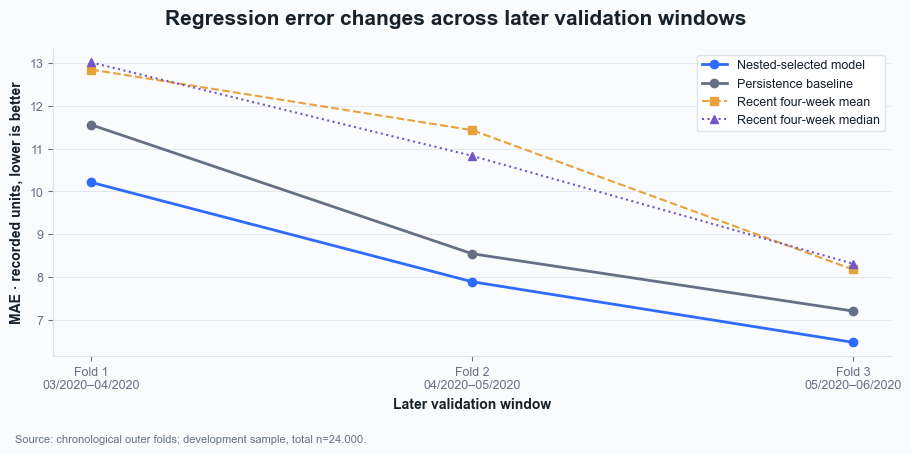

In [4]:
regression_summary = pd.DataFrame(
    [
        {
            "method": "Nested-selected model",
            "mean_MAE": regression_outer_results["model_MAE"].mean(),
            "sd_MAE_between_folds": regression_outer_results["model_MAE"].std(ddof=1),
            "mean_RMSE": regression_outer_results["model_RMSE"].mean(),
            "mean_R2": regression_outer_results["model_R2"].mean(),
        },
        {
            "method": "Persistence baseline",
            "mean_MAE": regression_outer_results["persistence_MAE"].mean(),
            "sd_MAE_between_folds": regression_outer_results["persistence_MAE"].std(ddof=1),
            "mean_RMSE": regression_outer_results["persistence_RMSE"].mean(),
            "mean_R2": regression_outer_results["persistence_R2"].mean(),
        },
        {
            "method": "Recent four-week mean baseline",
            "mean_MAE": regression_outer_results["recent_mean_MAE"].mean(),
            "sd_MAE_between_folds": regression_outer_results["recent_mean_MAE"].std(ddof=1),
            "mean_RMSE": regression_outer_results["recent_mean_RMSE"].mean(),
            "mean_R2": regression_outer_results["recent_mean_R2"].mean(),
        },
        {
            "method": "Recent four-week median baseline",
            "mean_MAE": regression_outer_results["recent_median_MAE"].mean(),
            "sd_MAE_between_folds": regression_outer_results["recent_median_MAE"].std(ddof=1),
            "mean_RMSE": regression_outer_results["recent_median_RMSE"].mean(),
            "mean_R2": regression_outer_results["recent_median_R2"].mean(),
        },
    ]
).set_index("method")
display_es(regression_outer_results[
    ["outer_fold", "validation_start", "validation_end", "selected_candidate", "n",
     "model_MAE", "persistence_MAE", "recent_mean_MAE", "recent_median_MAE",
     "model_RMSE", "model_R2",
     "model_negative_raw_prediction_share"]
].round(3))
display_es(regression_summary.round(3))

fold_labels = [
    f"Fold {row.outer_fold}\n{row.validation_start:%m/%Y}–{row.validation_end:%m/%Y}"
    for row in regression_outer_results.itertuples()
]
positions = np.arange(len(fold_labels))
fig, axis = plt.subplots(figsize=(9, 4.5))
axis.plot(positions, regression_outer_results["model_MAE"], marker="o", linewidth=2, color=BLUE, label="Nested-selected model")
axis.plot(positions, regression_outer_results["persistence_MAE"], marker="o", linewidth=2, color=MUTED, label="Persistence baseline")
axis.plot(positions, regression_outer_results["recent_mean_MAE"], marker="s", linewidth=1.5, linestyle="--", color=GOLD, label="Recent four-week mean")
axis.plot(positions, regression_outer_results["recent_median_MAE"], marker="^", linewidth=1.5, linestyle=":", color=VIOLET, label="Recent four-week median")
axis.set_xticks(positions, fold_labels)
axis.set_xlabel("Later validation window", fontsize=10, fontweight="bold")
axis.set_ylabel("MAE · recorded units, lower is better", fontsize=10, fontweight="bold")
add_title(fig, "Regression error changes across later validation windows")
axis.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=9)
style_axis(axis)
add_source(fig, f"Source: chronological outer folds; development sample, total n={es(int(regression_outer_results['n'].sum())):,}.")
figure_dir = ROOT / "results" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
figure_stem = f"07_nested_temporal_cv_{run_dir.name}_regression_outer"
fig.savefig(figure_dir / f"{figure_stem}.svg", bbox_inches="tight", facecolor=PAPER)
fig.savefig(figure_dir / f"{figure_stem}.png", dpi=300, bbox_inches="tight", facecolor=PAPER)
plt.show()


### Reading the regression results for this run

Across the three later validation windows, the nested procedure selected **Boosting with absolute-error loss every time**. Its mean MAE was **8,187 units per article-week**, compared with **9,101** for repeating current-week sales, **10,819** for the recent four-week mean, and **10,720** for the recent four-week median. Lower MAE means smaller average mistakes. The error changes by window (10,211, 7,897, and 6,454), so the three-window average should not be read as a guarantee for every future period.


### 4.1. How error changes with observed sales

The four fixed models below are Random Forest and all three Boosting losses. Each is fitted on the past weeks of an outer fold and evaluated on that fold's later weeks. These extra outer scores describe model behaviour; they do **not** replace inner-fold selection or determine the final configuration.

The four non-overlapping groups are **0**, **1–5**, **6–20**, and **more than 20** observed next-week units. Together they contain every evaluated article-week. The additional **0–20** line combines the first three groups, so it overlaps them; articles with exactly 20 units are included in both 6–20 and 0–20. Group membership is determined only after prediction and is never used as an input feature.

MAE is the average absolute error in units. The underprediction rate is the share of rows where predicted sales are below actual sales. Mean signed error is `prediction − actual`: negative values mean predictions are too low on average. A small signed error can still hide large individual mistakes, so read it alongside MAE.

**Code walkthrough.** The next cell sorts the saved outer predictions into sales groups and calculates how far each fixed model was from the observed value.


In [5]:
# Combine predictions made for the same outer validation rows by each fixed model.
diagnostic_predictions = pd.concat(
    regression_outer_candidate_predictions, ignore_index=True
)
expected_names = set(REGRESSION_DIAGNOSTIC_CANDIDATES)
if set(diagnostic_predictions["candidate"]) != expected_names:
    raise ValueError("One or more diagnostic models have no outer predictions.")
if diagnostic_predictions.groupby("candidate").size().nunique() != 1:
    raise ValueError("The diagnostic models were not evaluated on the same number of rows.")

MODEL_LABELS = {
    "random_forest_depth_12": "Random Forest",
    "boosting_squared_error": "Boosting · squared error",
    "boosting_absolute_error": "Boosting · absolute error",
    "boosting_poisson": "Boosting · Poisson",
}
SEGMENT_ORDER = ["All rows", "0", "1–5", "6–20", ">20", "0–20"]

def sales_segments(actual):
    """Return exhaustive disjoint groups plus one overlapping 0–20 subtotal."""
    return {
        "All rows": actual.ge(0),
        "0": actual.eq(0),
        "1–5": actual.between(1, 5),
        "6–20": actual.between(6, 20),
        ">20": actual.gt(20),
        "0–20": actual.between(0, 20),
    }

comparison_rows = []
fold_comparison_rows = []
for candidate_name in REGRESSION_DIAGNOSTIC_CANDIDATES:
    candidate_rows = diagnostic_predictions.loc[
        diagnostic_predictions["candidate"].eq(candidate_name)
    ]
    masks = sales_segments(candidate_rows["actual"])
    if not pd.concat([masks[group] for group in ["0", "1–5", "6–20", ">20"]], axis=1).sum(axis=1).eq(1).all():
        raise ValueError("The four sales groups must include each row exactly once.")
    for segment_name in SEGMENT_ORDER:
        segment_rows = candidate_rows.loc[masks[segment_name]]
        if segment_rows.empty:
            comparison_rows.append({
                "candidate": candidate_name, "segment": segment_name, "n": 0,
                "MAE": np.nan, "underprediction_rate": np.nan,
                "mean_signed_error": np.nan,
            })
            continue
        signed_error = segment_rows["predicted"] - segment_rows["actual"]
        comparison_rows.append({
            "candidate": candidate_name,
            "segment": segment_name,
            "n": len(segment_rows),
            "MAE": signed_error.abs().mean(),
            "underprediction_rate": signed_error.lt(0).mean(),
            "mean_signed_error": signed_error.mean(),
        })
    for fold_number, fold_rows in candidate_rows.groupby("outer_fold", sort=True):
        fold_masks = sales_segments(fold_rows["actual"])
        for segment_name in ["All rows", "0–20", ">20"]:
            segment_rows = fold_rows.loc[fold_masks[segment_name]]
            fold_comparison_rows.append({
                "outer_fold": fold_number,
                "candidate": candidate_name,
                "segment": segment_name,
                "n": len(segment_rows),
                "MAE": (
                    (segment_rows["predicted"] - segment_rows["actual"]).abs().mean()
                    if len(segment_rows) else np.nan
                ),
            })

sales_comparison = pd.DataFrame(comparison_rows)
fold_sales_comparison = pd.DataFrame(fold_comparison_rows)
print("Diagnostic rows per model:", format_number(len(diagnostic_predictions) // len(REGRESSION_DIAGNOSTIC_CANDIDATES)))
print("All four sales bands are exhaustive; 0–20 is an overlapping subtotal.")


Diagnostic rows per model: 24.000
All four sales bands are exhaustive; 0–20 is an overlapping subtotal.


### 4.2. Compare the four models across every sales group

The first table gives the number of article-weeks in each group. Each model uses those same rows. The next tables show MAE, underprediction rate, and average signed error; lower MAE is better. The final table shows MAE separately in each outer period, because an overall average can hide changes over time. The 0–20 subtotal is repeated intentionally and must not be added to the four disjoint groups.

**Code walkthrough.** The next cell displays the number of rows, MAE, underprediction rate, and signed error for every group and model. It also shows how MAE changes between outer windows.


In [6]:
def comparison_matrix(metric):
    matrix = sales_comparison.pivot(
        index="candidate", columns="segment", values=metric
    )
    return matrix.reindex(
        index=REGRESSION_DIAGNOSTIC_CANDIDATES, columns=SEGMENT_ORDER
    ).rename(index=MODEL_LABELS)

population = sales_comparison.loc[
    sales_comparison["candidate"].eq(REGRESSION_DIAGNOSTIC_CANDIDATES[0]),
    ["segment", "n"],
].set_index("segment").reindex(SEGMENT_ORDER)
print("Article-weeks in each group (0–20 overlaps the four disjoint groups):")
display_es(population.rename(columns={"n": "Rows"}))

print("MAE by model and observed next-week sales group · units; lower is better:")
display_es(comparison_matrix("MAE").round(3))

print("Rows underpredicted by model and group · percentage:")
display_es((comparison_matrix("underprediction_rate") * 100).round(1))

print("Mean prediction - actual (units); negative means too few predicted:")
display_es(comparison_matrix("mean_signed_error").round(3))

fold_mae = fold_sales_comparison.pivot(
    index="candidate", columns=["segment", "outer_fold"], values="MAE"
).reindex(
    index=REGRESSION_DIAGNOSTIC_CANDIDATES,
    columns=pd.MultiIndex.from_product(
        [["All rows", "0–20", ">20"], range(1, OUTER_FOLDS + 1)],
        names=["segment", "outer_fold"],
    ),
).rename(index=MODEL_LABELS)
print("MAE in each outer validation period · units; lower is better:")
display_es(fold_mae.round(3))


Article-weeks in each group (0–20 overlaps the four disjoint groups):


,Rows
segment,
All rows,24.000
0,5.086
1–5,8.890
6–20,5.677
>20,4.347
0–20,19.653


MAE by model and observed next-week sales group · units; lower is better:


segment,All rows,0,1–5,6–20,>20,0–20
candidate,,,,,,
Random Forest,"8,572","2,06","2,559","6,613","31,046","3,601"
Boosting · squared error,"8,503","2,268","2,414","6,375","31,031","3,52"
Boosting · absolute error,"8,19","1,237","2,114","6,03","31,572","3,018"
Boosting · Poisson,"8,381","1,956","2,345","6,253","31,022","3,373"


Rows underpredicted by model and group · percentage:


segment,All rows,0,1–5,6–20,>20,0–20
candidate,,,,,,
Random Forest,"38,8",0,"39,6","53,8",63,"33,5"
Boosting · squared error,"37,4",0,"34,4","54,8","64,4","31,4"
Boosting · absolute error,"48,9",0,"55,2","65,6","71,5","43,9"
Boosting · Poisson,40,0,"39,7","56,5",66,"34,3"


Mean prediction - actual (units); negative means too few predicted:


segment,All rows,0,1–5,6–20,>20,0–20
candidate,,,,,,
Random Forest,"-0,475","2,06","1,635","1,893","-10,85","1,82"
Boosting · squared error,"-0,664","2,268","1,586","1,493","-11,516","1,736"
Boosting · absolute error,"-3,003","1,237","0,566","-0,358","-18,715","0,473"
Boosting · Poisson,"-1,015","1,956","1,437","1,279","-12,502","1,526"


MAE in each outer validation period · units; lower is better:


### Reading the sales-group comparison for this run

Each of the four fixed models was evaluated on the same **24.000 outer-validation article-weeks**. The non-overlapping groups contain 5.086 rows with 0 sales, 8.890 with 1–5, 5.677 with 6–20, and 4.347 with more than 20. The 0–20 subtotal contains 19.653 rows and repeats the first three groups for convenience.

Absolute-error Boosting had the lowest overall MAE (**8,187**) and the lowest 0–20 MAE (**3,024**). For more than 20 sales, squared-error Boosting had the lowest MAE of these four fixed models (**30,930**), while absolute-error Boosting reached **31,530** and predicted too few units in **71,2 %** of those rows. The model that is best overall is therefore not the best for every sales level. These groups are defined from observed outcomes for diagnosis only; they are never predictors.


## 5. Classification search space and inner-loop tuning

Classification uses logistic regression, a constrained decision tree, and a small Random Forest, with two settings for the linear and tree models and one compact Random Forest setting. The inner loop selects by average precision (PR-AUC); the outer fold then evaluates the selected complete pipeline on later weeks. Class labels use the fixed unit threshold published by notebook 02. We do not tune a probability threshold in the outer evaluation.

**Code walkthrough.** The next cell repeats the inner/outer time-window process for high-demand classification. It selects by PR-AUC, a score suited to an uneven class balance.


In [7]:
CLASSIFICATION_CANDIDATES = {
    "logistic_C_0.1": LogisticRegression(
        C=0.1, solver="liblinear", max_iter=250, random_state=RANDOM_STATE
    ),
    "logistic_C_1": LogisticRegression(
        C=1.0, solver="liblinear", max_iter=250, random_state=RANDOM_STATE
    ),
    "tree_depth_8": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=100, class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "tree_depth_12": DecisionTreeClassifier(
        max_depth=12, min_samples_leaf=100, class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "random_forest_depth_12": RandomForestClassifier(
        n_estimators=30, max_depth=12, min_samples_leaf=100,
        max_features="sqrt", class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE,
    ),
}

classification_inner_rows = []
classification_outer_rows = []
classification_outer_predictions = []

for outer_fold in outer_folds:
    inner_folds = make_inner_folds(outer_fold["train_weeks"])
    candidate_scores = []
    for candidate_name, estimator in CLASSIFICATION_CANDIDATES.items():
        fold_scores = []
        for inner_fold in inner_folds:
            inner_train = rows_for_weeks(development, inner_fold["train_weeks"])
            inner_validation = rows_for_weeks(development, inner_fold["validation_weeks"])
            if inner_train[TARGET_CLASS].nunique() != 2 or inner_validation[TARGET_CLASS].nunique() != 2:
                raise ValueError("An inner classification fold does not contain both classes.")
            pipeline = make_pipeline(estimator)
            started = perf_counter()
            pipeline.fit(
                feature_frame(inner_train),
                inner_train[TARGET_CLASS].to_numpy(dtype="int8"),
            )
            fit_seconds = perf_counter() - started
            probability = pipeline.predict_proba(feature_frame(inner_validation))[:, 1]
            score = average_precision_score(
                inner_validation[TARGET_CLASS], probability
            )
            fold_scores.append(score)
            classification_inner_rows.append(
                {
                    "outer_fold": outer_fold["fold"],
                    "candidate": candidate_name,
                    "inner_fold": inner_fold["fold"],
                    "train_end": inner_fold["train_weeks"].max(),
                    "validation_start": inner_fold["validation_weeks"].min(),
                    "validation_end": inner_fold["validation_weeks"].max(),
                    "validation_rows": len(inner_validation),
                    "PR-AUC": score,
                    "fit_seconds": fit_seconds,
                }
            )
        candidate_scores.append(
            {
                "candidate": candidate_name,
                "mean_inner_PR_AUC": float(np.mean(fold_scores)),
            }
        )

    inner_score_table = pd.DataFrame(candidate_scores).sort_values(
        "mean_inner_PR_AUC", ascending=False
    )
    selected_candidate = inner_score_table.iloc[0]["candidate"]
    outer_train = rows_for_weeks(development, outer_fold["train_weeks"])
    outer_validation = rows_for_weeks(development, outer_fold["validation_weeks"])
    if outer_train[TARGET_CLASS].nunique() != 2 or outer_validation[TARGET_CLASS].nunique() != 2:
        raise ValueError("An outer classification fold does not contain both classes.")
    selected_pipeline = make_pipeline(CLASSIFICATION_CANDIDATES[selected_candidate])
    selected_pipeline.fit(
        feature_frame(outer_train), outer_train[TARGET_CLASS].to_numpy(dtype="int8")
    )
    probability = selected_pipeline.predict_proba(feature_frame(outer_validation))[:, 1]
    metrics = classification_metrics(outer_validation[TARGET_CLASS], probability)
    baseline_probability = outer_validation["sales"].ge(HIGH_DEMAND_THRESHOLD).astype(float)
    baseline_metrics = classification_metrics(
        outer_validation[TARGET_CLASS], baseline_probability
    )
    classification_outer_rows.append(
        {
            "outer_fold": outer_fold["fold"],
            "validation_start": outer_fold["validation_weeks"].min(),
            "validation_end": outer_fold["validation_weeks"].max(),
            "selected_candidate": selected_candidate,
            "n": len(outer_validation),
            **{f"model_{key}": value for key, value in metrics.items()},
            **{f"current_sales_{key}": value for key, value in baseline_metrics.items()},
        }
    )
    classification_outer_predictions.append(
        {
            "outer_fold": outer_fold["fold"],
            "actual": outer_validation[TARGET_CLASS].to_numpy(),
            "probability": probability,
        }
    )
    print(
        f"Classification outer fold {outer_fold['fold']}: selected {selected_candidate}; "
        f"PR-AUC={es(metrics['PR-AUC']):.3f}, current-sales PR-AUC={es(baseline_metrics['PR-AUC']):.3f}"
    )

classification_inner_scores = pd.DataFrame(classification_inner_rows)
classification_outer_results = pd.DataFrame(classification_outer_rows)
display_es(
    classification_inner_scores.groupby("candidate")["PR-AUC"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
    .round(3)
)
display_es(classification_outer_results.round(3))


Classification outer fold 1: selected logistic_C_0.1; PR-AUC=0,866, current-sales PR-AUC=0,668
Classification outer fold 2: selected logistic_C_1; PR-AUC=0,866, current-sales PR-AUC=0,679
Classification outer fold 3: selected logistic_C_1; PR-AUC=0,900, current-sales PR-AUC=0,719


,mean,std
candidate,,
logistic_C_1,"0,871","0,023"
logistic_C_0.1,"0,871","0,023"
tree_depth_8,"0,864","0,023"
tree_depth_12,"0,859","0,024"
random_forest_depth_12,"0,825","0,035"


,outer_fold,validation_start,validation_end,selected_candidate,n,model_precision_at_0.5,model_recall_at_0.5,model_F1_at_0.5,model_PR-AUC,model_ROC-AUC,model_Brier,current_sales_precision_at_0.5,current_sales_recall_at_0.5,current_sales_F1_at_0.5,current_sales_PR-AUC,current_sales_ROC-AUC,current_sales_Brier
0,1,2020-03-23 00:00:00,2020-04-13 00:00:00,logistic_C_0.1,8.000,"0,852","0,709","0,774","0,866","0,952","0,07","0,778","0,802","0,79","0,668","0,868","0,094"
1,2,2020-04-20 00:00:00,2020-05-11 00:00:00,logistic_C_1,8.000,"0,856","0,707","0,775","0,866","0,95","0,068","0,791","0,803","0,797","0,679","0,871","0,092"
2,3,2020-05-18 00:00:00,2020-06-08 00:00:00,logistic_C_1,8.000,"0,908","0,719","0,802","0,9","0,962","0,059","0,818","0,834","0,826","0,719","0,891","0,078"


## 6. Classification outer-loop estimates

The outer rows evaluate the entire selection procedure on weeks that were not used by that fold's inner search. PR-AUC is the primary ranking metric. F1, precision, and recall use the fixed 0,5 probability threshold; Brier evaluates the predicted probabilities and does not use a decision threshold. The current-sales rule is the simple baseline. Fold-to-fold changes reveal temporal variation, not a causal effect or a formal confidence interval.

**Code walkthrough.** The next cell summarizes classification quality across outer windows and compares the selected model with a simple current-sales rule.


,outer_fold,validation_start,validation_end,selected_candidate,n,model_PR-AUC,current_sales_PR-AUC,model_F1_at_0.5,model_ROC-AUC,model_Brier
0,1,2020-03-23 00:00:00,2020-04-13 00:00:00,logistic_C_0.1,8.000,"0,866","0,668","0,774","0,952","0,07"
1,2,2020-04-20 00:00:00,2020-05-11 00:00:00,logistic_C_1,8.000,"0,866","0,679","0,775","0,95","0,068"
2,3,2020-05-18 00:00:00,2020-06-08 00:00:00,logistic_C_1,8.000,"0,9","0,719","0,802","0,962","0,059"


,mean_PR_AUC,sd_PR_AUC_between_folds,mean_F1_at_0.5,mean_ROC_AUC,mean_Brier
method,,,,,
Nested-selected model,"0,877","0,02","0,784","0,955","0,065"
Current-sales rule,"0,689","0,027","0,804","0,877","0,088"


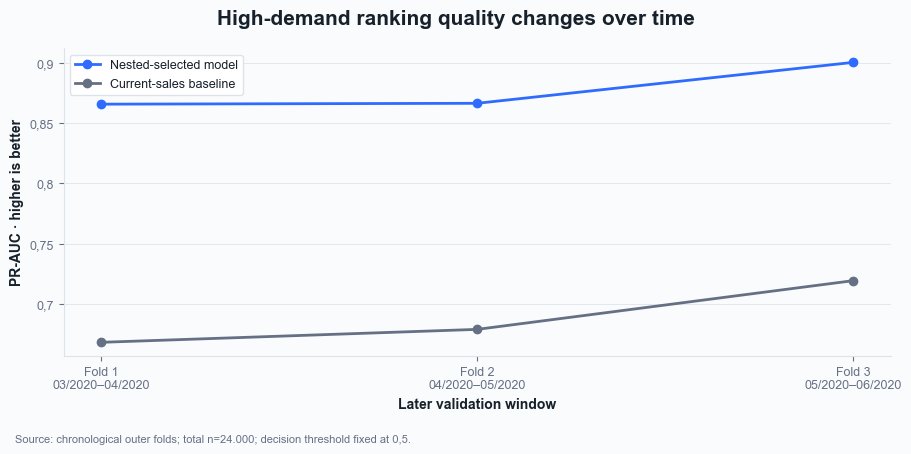

In [8]:
classification_summary = pd.DataFrame(
    [
        {
            "method": "Nested-selected model",
            "mean_PR_AUC": classification_outer_results["model_PR-AUC"].mean(),
            "sd_PR_AUC_between_folds": classification_outer_results["model_PR-AUC"].std(ddof=1),
            "mean_F1_at_0.5": classification_outer_results["model_F1_at_0.5"].mean(),
            "mean_ROC_AUC": classification_outer_results["model_ROC-AUC"].mean(),
            "mean_Brier": classification_outer_results["model_Brier"].mean(),
        },
        {
            "method": "Current-sales rule",
            "mean_PR_AUC": classification_outer_results["current_sales_PR-AUC"].mean(),
            "sd_PR_AUC_between_folds": classification_outer_results["current_sales_PR-AUC"].std(ddof=1),
            "mean_F1_at_0.5": classification_outer_results["current_sales_F1_at_0.5"].mean(),
            "mean_ROC_AUC": classification_outer_results["current_sales_ROC-AUC"].mean(),
            "mean_Brier": classification_outer_results["current_sales_Brier"].mean(),
        },
    ]
).set_index("method")
display_es(classification_outer_results[
    ["outer_fold", "validation_start", "validation_end", "selected_candidate", "n",
     "model_PR-AUC", "current_sales_PR-AUC", "model_F1_at_0.5",
     "model_ROC-AUC", "model_Brier"]
].round(3))
display_es(classification_summary.round(3))

fold_labels = [
    f"Fold {row.outer_fold}\n{row.validation_start:%m/%Y}–{row.validation_end:%m/%Y}"
    for row in classification_outer_results.itertuples()
]
positions = np.arange(len(fold_labels))
fig, axis = plt.subplots(figsize=(9, 4.5))
axis.plot(positions, classification_outer_results["model_PR-AUC"], marker="o", linewidth=2, color=BLUE, label="Nested-selected model")
axis.plot(positions, classification_outer_results["current_sales_PR-AUC"], marker="o", linewidth=2, color=MUTED, label="Current-sales baseline")
axis.set_xticks(positions, fold_labels)
axis.set_xlabel("Later validation window", fontsize=10, fontweight="bold")
axis.set_ylabel("PR-AUC · higher is better", fontsize=10, fontweight="bold")
add_title(fig, "High-demand ranking quality changes over time")
axis.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=9)
style_axis(axis)
add_source(fig, f"Source: chronological outer folds; total n={es(int(classification_outer_results['n'].sum())):,}; decision threshold fixed at 0,5.")
figure_dir = ROOT / "results" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
figure_stem = f"07_nested_temporal_cv_{run_dir.name}_classification_outer"
fig.savefig(figure_dir / f"{figure_stem}.svg", bbox_inches="tight", facecolor=PAPER)
fig.savefig(figure_dir / f"{figure_stem}.png", dpi=300, bbox_inches="tight", facecolor=PAPER)
plt.show()


### Reading the classification results for this run

The selected classifiers reached mean **PR-AUC 0,877** across the three later windows, versus **0,689** for the simple current-sales rule. Higher PR-AUC means better ranking of articles likely to have high demand. At the fixed probability cutoff of 0,5, however, the simple rule has slightly higher mean F1 (**0,804** versus **0,784**). A better ranking score does not automatically give the best 0,5-cutoff score; no cutoff was tuned using outer validation or test outcomes.


## 7. Configuration selection and stability

For the final refit, choose the configuration with the best average inner-fold score across all outer searches: lowest MAE for regression and highest PR-AUC for classification. This development-only aggregation avoids using the outer validation scores to choose a hyperparameter after the outer performance estimate is known. The outer winners also show whether different temporal folds prefer different settings.

**Code walkthrough.** The next cell checks which settings won repeatedly and selects final regression and classification settings using development data only.


In [9]:
regression_configuration_stability = (
    regression_inner_scores.groupby("candidate")["MAE"]
    .agg(mean_inner_MAE="mean", sd_inner_MAE="std")
    .sort_values("mean_inner_MAE")
)
classification_configuration_stability = (
    classification_inner_scores.groupby("candidate")["PR-AUC"]
    .agg(mean_inner_PR_AUC="mean", sd_inner_PR_AUC="std")
    .sort_values("mean_inner_PR_AUC", ascending=False)
)
regression_winner_frequency = regression_outer_results["selected_candidate"].value_counts().rename("outer_fold_wins")
classification_winner_frequency = classification_outer_results["selected_candidate"].value_counts().rename("outer_fold_wins")

regression_stability = regression_configuration_stability.join(regression_winner_frequency, how="left").fillna({"outer_fold_wins": 0})
classification_stability = classification_configuration_stability.join(classification_winner_frequency, how="left").fillna({"outer_fold_wins": 0})

selected_regression_candidate = regression_stability.index[0]
selected_classification_candidate = classification_stability.index[0]
print("Final regression configuration:", selected_regression_candidate)
print("Final classification configuration:", selected_classification_candidate)
display_es(regression_stability.round(3))
display_es(classification_stability.round(3))
display_es(
    pd.DataFrame(
        {
            "outer_fold": regression_outer_results["outer_fold"],
            "regression_winner": regression_outer_results["selected_candidate"],
            "classification_winner": classification_outer_results["selected_candidate"],
        }
    )
)


Final regression configuration: boosting_absolute_error
Final classification configuration: logistic_C_1


,mean_inner_MAE,sd_inner_MAE,outer_fold_wins
candidate,,,
boosting_absolute_error,"7,496","3,159",3
boosting_squared_error,"8,024","3,087",0
boosting_poisson,"8,043","3,055",0
random_forest_depth_12,"8,047","3,163",0
tree_depth_8,"8,338","3,24",0
tree_depth_12,"8,38","3,179",0
ridge_alpha_10,"8,896","2,938",0
ridge_alpha_1,"8,899","2,939",0


,mean_inner_PR_AUC,sd_inner_PR_AUC,outer_fold_wins
candidate,,,
logistic_C_1,"0,871","0,023",2
logistic_C_0.1,"0,871","0,023",1
tree_depth_8,"0,864","0,023",0
tree_depth_12,"0,859","0,024",0
random_forest_depth_12,"0,825","0,035",0


,outer_fold,regression_winner,classification_winner
0,1,boosting_absolute_error,logistic_C_0.1
1,2,boosting_absolute_error,logistic_C_1
2,3,boosting_absolute_error,logistic_C_1


## 8. Final-test evaluation and interpretation limit

The selected configurations are refitted on every published train + validation row and scored on every published test row. The temporal search above remains sampled to keep repeated model fitting tractable. The final refit uses the same selected configuration and preprocessing pipeline; the larger training set can change its predictions and metrics. Regression predictions below zero are clipped to zero under the same policy as the outer folds.

**Interpretation limit:** An earlier version of this notebook already displayed test outcomes before the regression candidate space was expanded. The updated test scores are therefore exploratory, not a fresh untouched holdout estimate. Do not use them to choose another model or setting. The outer temporal folds remain the main evidence for comparing the expanded candidate set; a future confirmatory test would require new, unseen data.

**Decision-threshold policy.** Notebook 06 chose 0,30 by validation F1 for its own 100.000-row logistic fit. This notebook uses a separate temporal search, refits the selected classifier on all development rows, and reports precision, recall, and F1 at a fixed 0,5 cutoff. Its ranking metrics (PR-AUC and ROC-AUC) do not depend on that cutoff. Do not transfer 0,30 automatically or tune a new cutoff using test results.

**Code walkthrough.** The next cell loads every published train, validation, and test row, refits the selected configurations on full development data, and scores the full test partition. It also exports exact metrics, configuration, and data provenance as JSON under `results/metrics/`. The exported test scores remain exploratory because outcomes from this period were previously inspected.


In [ ]:
# The temporal search above uses a fixed weekly sample. The final refit and
# exploratory test score below use every published development/test row.
full_parts = []
full_columns = list(dict.fromkeys([column for column in SAMPLED_COLUMNS if column != "article_id"]))
for full_chunk in pd.read_csv(
    dataset_path, usecols=full_columns, parse_dates=["target_week"], chunksize=CHUNK_SIZE
):
    full_chunk = full_chunk.loc[full_chunk["split"].isin(["train", "validation", "test"])].copy()
    if not full_chunk.empty:
        full_parts.append(full_chunk)
if not full_parts:
    raise ValueError("No rows found for the full-data final refit.")
full_data = pd.concat(full_parts, ignore_index=True)
del full_parts
expected_counts = summary["split_counts"]
for partition in ("train", "validation", "test"):
    actual_count = int(full_data["split"].eq(partition).sum())
    if actual_count != expected_counts[partition]:
        raise ValueError(f"{partition}: {actual_count} rows, expected {expected_counts[partition]}.")
if full_data[["split", "target_week", TARGET_REGRESSION, TARGET_CLASS]].isna().any().any():
    raise ValueError("Full-data final evaluation contains missing labels or dates.")
if not full_data[TARGET_REGRESSION].ge(0).all():
    raise ValueError("Sales targets must be nonnegative.")
if not full_data[TARGET_CLASS].eq(
    full_data[TARGET_REGRESSION].ge(HIGH_DEMAND_THRESHOLD).astype("int8")
).all():
    raise ValueError("Full-data class labels do not match the fixed threshold.")
full_data["week_sin"] = np.sin(2 * np.pi * (full_data["iso_week"] - 1) / 52.1775)
full_data["week_cos"] = np.cos(2 * np.pi * (full_data["iso_week"] - 1) / 52.1775)
for column in CATEGORICAL_FEATURES:
    full_data[column] = full_data[column].fillna("Unknown").astype(str)
full_development = full_data.loc[full_data["split"].isin(["train", "validation"])].copy()
full_test = full_data.loc[full_data["split"].eq("test")].copy()
del full_data
if full_development["target_week"].max() >= full_test["target_week"].min():
    raise ValueError("Final development and test periods overlap.")
if full_test[TARGET_CLASS].nunique() != 2:
    raise ValueError("The full test partition must contain both classes.")
print(f"Full-data final refit: {es(len(full_development)):,} development rows; "
      f"exploratory evaluation: {es(len(full_test)):,} test rows.")

regression_final_model = make_pipeline(
    REGRESSION_CANDIDATES[selected_regression_candidate]
)
classification_final_model = make_pipeline(
    CLASSIFICATION_CANDIDATES[selected_classification_candidate]
)

development_started = perf_counter()
regression_final_model.fit(
    feature_frame(full_development), full_development[TARGET_REGRESSION].to_numpy()
)
regression_final_fit_seconds = perf_counter() - development_started

development_started = perf_counter()
classification_final_model.fit(
    feature_frame(full_development), full_development[TARGET_CLASS].to_numpy(dtype="int8")
)
classification_final_fit_seconds = perf_counter() - development_started

test_regression_prediction_raw = regression_final_model.predict(feature_frame(full_test))
test_regression_metrics = regression_metrics(
    full_test[TARGET_REGRESSION], test_regression_prediction_raw
)
test_classification_probability = classification_final_model.predict_proba(
    feature_frame(full_test)
)[:, 1]
test_classification_metrics = classification_metrics(
    full_test[TARGET_CLASS], test_classification_probability
)

test_regression_baseline = regression_metrics(
    full_test[TARGET_REGRESSION], full_test["sales"]
)
test_classification_baseline_probability = (
    full_test["sales"].ge(HIGH_DEMAND_THRESHOLD).astype(float)
)
test_classification_baseline = classification_metrics(
    full_test[TARGET_CLASS], test_classification_baseline_probability
)

final_test_results = pd.DataFrame(
    [
        {
            "task": "Regression",
            "method": selected_regression_candidate,
            "n_test_rows": len(full_test),
            **test_regression_metrics,
            "fit_seconds": regression_final_fit_seconds,
        },
        {
            "task": "Regression",
            "method": "Persistence baseline",
            "n_test_rows": len(full_test),
            **test_regression_baseline,
            "fit_seconds": np.nan,
        },
        {
            "task": "Classification",
            "method": selected_classification_candidate,
            "n_test_rows": len(full_test),
            **test_classification_metrics,
            "fit_seconds": classification_final_fit_seconds,
        },
        {
            "task": "Classification",
            "method": "Current-sales rule",
            "n_test_rows": len(full_test),
            **test_classification_baseline,
            "fit_seconds": np.nan,
        },
    ]
)
# Save exact, machine-readable results only after the complete refit and scoring succeed.
# No model is serialized here: the full pipeline can be rebuilt from this notebook
# and the versioned processed publication. Test results remain exploratory.
metrics_dir = ROOT / "results" / "metrics"
metrics_dir.mkdir(parents=True, exist_ok=True)
metrics_path = metrics_dir / f"07_full_test_{run_dir.name}.json"
metrics_record = {
    "status": "exploratory_test_previously_inspected",
    "publication_run": run_dir.name,
    "publication_article_week_sha256": checksums[dataset_path.name],
    "random_state": RANDOM_STATE,
    "search_rows_per_target_week": MAX_ROWS_PER_WEEK,
    "outer_folds": OUTER_FOLDS,
    "outer_horizon_weeks": OUTER_HORIZON_WEEKS,
    "inner_folds": INNER_FOLDS,
    "inner_horizon_weeks": INNER_HORIZON_WEEKS,
    "full_development_rows": len(full_development),
    "full_test_rows": len(full_test),
    "high_demand_units_threshold": HIGH_DEMAND_THRESHOLD,
    "classification_probability_threshold": 0.5,
    "regression_candidate": selected_regression_candidate,
    "classification_candidate": selected_classification_candidate,
    "regression_estimator_parameters": REGRESSION_CANDIDATES[
        selected_regression_candidate
    ].get_params(deep=False),
    "classification_estimator_parameters": CLASSIFICATION_CANDIDATES[
        selected_classification_candidate
    ].get_params(deep=False),
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "outer_regression_results": json.loads(
        regression_outer_results.to_json(orient="records", date_format="iso", double_precision=15)
    ),
    "outer_classification_results": json.loads(
        classification_outer_results.to_json(orient="records", date_format="iso", double_precision=15)
    ),
    "full_test_results": json.loads(final_test_results.to_json(orient="records", double_precision=15)),
}
metrics_path.write_text(
    json.dumps(metrics_record, indent=2, ensure_ascii=False, allow_nan=False, default=str) + "\n",
    encoding="utf-8",
)
print("Exact metrics and configuration saved:", metrics_path)

print("Configurations were selected using development data only.")
print("Exploratory full test partition:", f"{es(len(full_test)):,}", "article-weeks")
# Separate the two tasks so the reader never sees irrelevant blank metric columns.
regression_test_table = final_test_results.loc[
    final_test_results["task"].eq("Regression"),
    ["method", "n_test_rows", "MAE", "RMSE", "R2"],
].set_index("method")
classification_test_table = final_test_results.loc[
    final_test_results["task"].eq("Classification"),
    ["method", "n_test_rows", "precision_at_0.5", "recall_at_0.5",
     "F1_at_0.5", "PR-AUC", "ROC-AUC", "Brier"],
].set_index("method")
print("Regression on the exploratory full test partition · lower MAE is better:")
display_es(regression_test_table.round(3))
print("Classification on the exploratory full test partition · higher PR-AUC is better:")
display_es(classification_test_table.round(3))

from sklearn.metrics import confusion_matrix, precision_recall_curve

test_prediction = (test_classification_probability >= 0.5).astype("int8")
test_confusion = confusion_matrix(
    full_test[TARGET_CLASS], test_prediction, labels=[0, 1]
)
precision_curve, recall_curve, _ = precision_recall_curve(
    full_test[TARGET_CLASS], test_classification_probability
)
test_prevalence = float(full_test[TARGET_CLASS].mean())

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
add_title(fig, "Exploratory test: high-demand classification")

image = axes[0].imshow(test_confusion, cmap="Blues")
for row in range(2):
    for column in range(2):
        # Use white text on dark cells so every count remains readable.
        count_color = "white" if image.norm(test_confusion[row, column]) > 0.55 else INK
        axes[0].text(column, row, f"{es(test_confusion[row, column]):,}",
                     ha="center", va="center", color=count_color, fontsize=10)
axes[0].set_xticks([0, 1], ["Not high", "High"])
axes[0].set_yticks([0, 1], ["Not high", "High"])
axes[0].set_xlabel("Prediction · 0.5 threshold", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Actual class", fontsize=10, fontweight="bold")
axes[0].set_title("Confusion matrix", fontsize=11, fontweight="bold")

axes[1].plot(recall_curve, precision_curve, color=BLUE, linewidth=2, label="Selected model")
axes[1].axhline(test_prevalence, color=MUTED, linestyle="--", linewidth=1.2, label="Positive-class prevalence")
axes[1].set_xlabel("Recall", fontsize=10, fontweight="bold")
axes[1].set_ylabel("Precision", fontsize=10, fontweight="bold")
axes[1].set_title("Precision–recall curve", fontsize=11, fontweight="bold")
axes[1].legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True)
axes[0].grid(False)  # Grid lines would cross the confusion-matrix counts.
style_axis(axes[1])
add_source(fig, f"Source: exploratory full test partition; n={es(len(full_test)):,}; prevalence={es(test_prevalence):.1%}; decision threshold=0,5.")
figure_dir = ROOT / "results" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
figure_stem = f"07_nested_temporal_cv_{run_dir.name}_final_test"
fig.savefig(figure_dir / f"{figure_stem}.svg", bbox_inches="tight", facecolor=PAPER)
fig.savefig(figure_dir / f"{figure_stem}.png", dpi=300, bbox_inches="tight", facecolor=PAPER)
plt.show()


Full-data final refit: 1.597.649 development rows; exploratory evaluation: 289.490 test rows.


### Reading the exploratory full-test results

The selected absolute-error Boosting regressor was refitted on all 1.597.649 development article-weeks and evaluated on all 289.490 test article-weeks. Its test MAE is **6,648** units, versus **7,849** for the persistence rule; lower is better. The selected logistic classifier has test **PR-AUC 0,893**, versus **0,687** for the current-sales rule. At the fixed 0,5 probability cutoff, logistic regression has **F1 0,801**, while the simple rule has **F1 0,807**. Thus the classifier ranks high-demand articles better overall, although the simple rule has slightly higher F1 at this particular cutoff.

The earlier 28.000-row test sample gave MAE 6,444 and PR-AUC 0,890. Those numbers are not directly comparable with the full-test scores: both the model fitting population and the evaluation population changed. Since test outcomes had already been viewed before this full-data refit, these full-test results remain exploratory. The outer temporal validation windows above are the main evidence for comparing candidates; no further model choice should be based on these test scores.
